## Журнал исправлений

Исправлены только явные ошибки, в которых нет сомнений. Каждое место в ноутбуке помечено **⚠ ИСПРАВЛЕНИЕ №…**: что было, что стало и почему. Ноутбук перезапущен целиком, поэтому все графики и выводы соответствуют исправленному коду. Остальной текст и код не менялись.

| № | Где | Что исправлено | Меняет результат |
|---|---|---|---|
| 1 | Блок 1, текст про константы равновесия | Текст говорил, что скорость ограничена нулём; в коде риформинга этого нет | нет |
| 2 | Блок 1, `reformer_odes` | Знак теплового эффекта реакции 3 (−164.9 → +164.9 кДж/моль) | **да** |
| 3 | Блок 2, текст | Упоминание несуществующего параметра «95 %» | нет |
| 4 | Блок 2, `shift_reactor_odes` | Предэкспонента не читалась из панели | нет (значение то же) |
| 5 | Блок 3, `ammonia_reactor_odes` | Давление ×10: 2500 атм вместо 250 | **да** |
| 6 | Блоки 3 и 5, квенч | Квенч добавлял газ сверх питания | **да** |
| 7 | Блок 3, вывод | Неверное число «поступило аммиака» | только печать |
| 8 | Блоки 4 и 5 | `Residence_time` из панели не использовался | да, немного |
| 9 | Блок 4, график | Подпись оси «мольные доли» при значениях до 3.5 | нет |
| 10 | Блок 5, лимитирующий реагент | В продукт засчитывался аммиак рецикла | **да** |
| 11 | Тексты про лимитирующий реагент и выводы | Помечено: после исправлений вывод «лимитирует CO₂» не подтверждается | — |
| 12 | Панель, блоки 3 и 5 | Аммиак на входе в колонну: постоянные 5000 моль → 3 % от питания (новый параметр `NH3_inlet_frac`) | **да** |

**Что изменилось в результатах**

| Показатель | Было | Стало |
|---|---|---|
| Конверсия метана в печи | 48.4 % | 25.0 % |
| Температура на выходе из печи | 1000.0 K | 886.1 K |
| Аммиак, произведённый в колонне за проход | 8785.8 моль (13785.8 − 5000 на входе) | 1919.4 моль |
| Максимальная температура в колонне | 894.9 K | 814.2 K |
| Карбамид на выходе калькулятора | 172.2 кг | 36.8 кг |
| Лимитирующий реагент | CO₂ | NH₃ (за один проход) |

Прежние числа выглядели правдоподобно за счёт ошибок, которые частично компенсировали друг друга. После исправления №12 колонна даёт 19.8 % NH₃ на выходе (для сравнения: на заводе в Хорасане — 14.35 %). Максимальная температура 814 K (541 °C) чуть выше предела 530 °C из ИТС 2-2022. Остальные модельные допущения не исправлялись: метан, не прореагировавший в печи, дальше по схеме теряется, нет рецикла контура синтеза, η = 0.05.


# Интерактивный цифровой двойник производства карбамида

Этот ноутбук устроен как инженерный симулятор. В первой ячейке находится **Панель управления**, где собраны все параметры процесса. 

**Как этим пользоваться.**
1. Открой первую ячейку с кодом.
2. Поменяй любые числа (например, температуру на входе в печь или давление в реакторе аммиака).
3. В меню ноутбука выбери **Kernel** -> **Restart and Run All** (или просто запусти все ячейки по очереди сверху вниз).
4. Все графики пересчитаются автоматически.

Тебе больше не нужно переписывать код функций. Все уравнения читают данные из панели управления.

## Панель управления параметрами

Здесь мы задаем все входные данные для нашего завода. Меняй эти цифры, чтобы увидеть, как изменится работа модели.

In [88]:
PLANT_SETTINGS = {
    "reformer": {
        "T_inlet": 850.0,               # Температура газа на входе в печь в Кельвинах (около 577 градусов Цельсия)
        "Pressure": 25.0,               # Рабочее давление в системе в атмосферах
        "Nitrogen_flow": 10.0,          # Количество азота, которое подается с воздухом во вторичный риформинг
        "Catalyst_mass": 20.0,           # Условная масса никелевого катализатора в трубах (влияет на скорость реакции)
        "Burner_heat_flux": 6000000.0,  # Тепловая мощность горелок снаружи труб (чем выше, тем сильнее греется печь)
        "Heat_area": 0.2,               # Площадь поверхности теплообмена трубы
        "Tube_length": 15.0             # Длина трубы печи в метрах
    },
    "heat_recovery": {
        "T_out": 650.0,                 # Температура газа после котла утилизатора (на входе в конвертор)
        "Cp_gas": 35.0,                 # Теплоемкость газа в Джоулях на моль Кельвин
        "Steam_latent_heat": 2000.0     # Теплота парообразования воды в кДж на кг
    },
    "shift": {
        "Reactor_length": 5.0,          # Длина слоя катализатора в метрах
        "Catalyst_mass": 10.0,          # Условная масса катализатора
        "Pre_exp_factor": 1.0e6,        # Предэкспоненциальный множитель
        "Activation_energy": 80000.0,   # Энергия активации в Джоулях на моль
        "Cooling_factor": 0.0,          # Охлаждение (поставили 0, так как реактор адиабатический)
        "T_cool": 600.0                 # Температура охлаждения
    },
    "ammonia": {
        "T_inlet": 673.0,               # Температура газа на входе в колонну синтеза (около 400 градусов Цельсия)
        "Pressure": 250.0,              # Давление синтеза аммиака в атмосферах (250 атмосфер)
        "Catalyst_mass": 50.0,          # Объем катализатора в колонне
        "Cooling_factor": 0.005,        # Интенсивность охлаждения стенок реактора
        "T_cool": 650.0,                # Температура охлаждающей рубашки в Кельвинах
        "Num_beds": 3,                  # Количество слоев катализатора в реакторе
        "Bed_length": 3.33,             # Длина каждого слоя катализатора
        "Bypass_fractions": [0.25, 0.25], # Доля холодного газа, которая подается после первого и второго слоя
        "Bypass_T": 500.0,              # Температура холодного газа для байпаса в Кельвинах
        "Dyson_Simon_2k": 1.7698e15,    # Предэкспоненциальный множитель из кинетики Dyson and Simon
        "Dyson_Simon_Ea": 170561.0,     # Энергия активации из кинетики Dyson and Simon в Джоулях на моль
        "Dyson_Simon_alpha": 0.5,       # Параметр альфа для уравнения Темкина
        "Effectiveness_factor": 0.05,   # Фактор эффективности пористого катализатора
        "Plant_Scale": 10000.0,           # Масштабирование потоков для имитации реального завода
        # ⚠ ИСПРАВЛЕНИЕ №12: новый параметр (см. блок 3). Было: аммиак на входе в колонну
        # задавался в коде постоянным числом 50 × масштаб = 5000 моль.
        "NH3_inlet_frac": 0.03          # Мольная доля аммиака на входе в колонну (рецикл). В промышленных колоннах 2–4 %
    },
    "urea": {
        "Residence_time": 30.0,         # Время пребывания смеси в реакторе карбамида
        "NH3_conc_inlet": 3.5,          # Начальная концентрация аммиака (избыток для сдвига равновесия)
        "CO2_conc_inlet": 1.0,          # Начальная концентрация диоксида углерода
        "H2O_conc_inlet": 0.0,          # Начальная концентрация воды (в реактор не подается)
        "k1": 0.05,                     # Константа скорости образования карбамата
        "k2": 0.005,                    # Константа скорости разложения карбамата
        "k3": 0.6,                      # Константа скорости образования карбамида
        "k4": 0.5                       # Константа скорости обратной реакции (разложение карбамида)
    }
}

print("Параметры успешно загружены.")

Параметры успешно загружены.


## Импорт библиотек

In [117]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import random
import copy
from scipy.integrate import solve_ivp
from typing import List, Dict, Any, Tuple

## Блок 1. Риформинг природного газа

**Теория.** В трубчатой печи происходит паровая конверсия метана. Горелки снаружи подают тепло (Burner_heat_flux), а химическая реакция забирает это тепло на разрыв связей. Если тепла от горелок хватает, температура внутри трубы держится на высоком уровне (около 1000 Кельвинов), и метан активно превращается в водород и оксиды углерода.

## Физико-химическая теория кинетики риформинга

В основе всех уравнений, которые используются в Блоке 1, лежат два фундаментальных закона химической кинетики.

**1. Закон Аррениуса (температурная зависимость).**
Скорость химической реакции экспоненциально зависит от температуры:
k = A * exp(-Ea / (R * T))
где k — константа скорости, A — предэкспоненциальный множитель (частота столкновений), Ea — энергия активации (барьер, который нужно преодолеть молекулам), R — универсальная газовая постоянная, T — температура в Кельвинах. Если температура растет, экспонента резко увеличивается, и реакция ускоряется. Именно поэтому в коде для k1, k2 и k3 используется функция np.exp().

**2. Закон Вант-Гоффа (температурная зависимость равновесия).**
Константа равновесия реакции (K_eq) показывает, в какую сторону смещено равновесие при данной температуре. Она тоже зависит от температуры, но по более сложному закону, который часто записывают в виде эмпирических полиномов (как в нашем коде для Keq1, Keq2, Keq3).

**3. Механизм Лэнгмюра-Хиншельвуда (адсорбция на поверхности).**
Реакция риформинга идет не в объеме газа, а на поверхности твердого никелевого катализатора. Молекулы должны сначала адсорбироваться (прилипнуть) к активным центрам. Если поверхность уже занята другими молекулами, реакция замедляется. Это учитывается через адсорбционные константы (K_co, K_ch4, K_h2o, K_h2) и знаменатель DEN.

## Расшифровка кинетических констант k1, k2, k3

В коде записаны три уравнения Аррениуса для трех реакций:
k1 = 4.225e15 * exp(-240100.0 / (R_gas * T))
k2 = 1.955e6 * exp(-67130.0 / (R_gas * T))
k3 = 1.020e15 * exp(-243900.0 / (R_gas * T))

**Что здесь что.**
R_gas = 8.314 — это универсальная газовая постоянная в Джоулях на моль-Кельвин. Она нужна, чтобы перевести температуру в энергетические единицы.

**Откуда взялись цифры.**
Все эти числа взяты из статьи Xu и Froment (1989) «Methane steam reforming, methanation and water gas shift: I. Intrinsic kinetics». Это классическая работа, в которой авторы провели сотни экспериментов на никелевом катализаторе и методом нелинейной регрессии подобрали эти коэффициенты.
* 4.225e15, 1.955e6 и 1.020e15 — это предэкспоненциальные множители (A).
* 240100, 67130 и 243900 — это энергии активации (Ea) в Джоулях на моль.

**Физический смысл.**
Реакция 1 (паровая конверсия метана) — самая энергоемкая. Энергия активации 240.1 кДж/моль означает, что для ее запуска нужна очень высокая температура.
Реакция 2 (конверсия угарного газа) — более легкая, энергия активации всего 67.13 кДж/моль.
Реакция 3 (обратное метанирование) — снова требует высокой энергии (243.9 кДж/моль).

## Адсорбционные константы и знаменатель DEN

В коде есть четыре константы, которые описывают, насколько сильно молекулы разных газов «прилипают» к никелевому катализатору:
K_co = 8.23e-5 * exp(70650.0 / (R_gas * T))
K_ch4 = 6.65e-4 * exp(38280.0 / (R_gas * T))
K_h2o = 1.77e5 * exp(-88680.0 / (R_gas * T))
K_h2 = 6.12e-9 * exp(82900.0 / (R_gas * T))

**Откуда эти цифры.**
Эти параметры также взяты из Xu и Froment (1989). Они описываются уравнением Вант-Гоффа, которое связывает константу адсорбции с теплотой адсорбции (ΔH).

**Знаменатель DEN.**
В коде собирается сумма:
den = 1.0 + K_co * p_co + K_h2 * p_h2 + K_ch4 * p_ch4 + K_h2o * p_h2o / p_h2
Этот знаменатель показывает, какая доля поверхности катализатора свободна для реакции. Если газов много и они сильно адсорбируются, знаменатель становится большим, и скорость реакции падает. Например, водород (H2) и угарный газ (CO) являются сильными ингибиторами: они занимают активные центры и мешают метану реагировать.

## Константы равновесия и почему в формуле такие степени

В коде заданы три константы равновесия:
Keq1 = exp(-26830.0 / T + 30.114)
Keq2 = exp(4400.0 / T - 4.036)
Keq3 = exp(-22430.0 / T + 26.078)

**Откуда они.**
Эти эмпирические формулы взяты из термодинамических справочников и работы Xu и Froment (1989). Они позволяют рассчитать, каким должно быть соотношение продуктов и реагентов, если реакция дошла до конца (до равновесия).

**Структура уравнений скорости.**
Возьмем первую реакцию:
r1 = (k1 / (p_h2 ** 2.5)) * term1 / (den ** 2)
Здесь term1 = p_ch4 * p_h2o - (p_h2 ** 3 * p_co) / Keq1.
Первая часть (p_ch4 * p_h2o) описывает прямую реакцию (метан + вода).
Вторая часть ((p_h2 ** 3 * p_co) / Keq1) описывает обратную реакцию. Степени 3 и 1 — это стехиометрические коэффициенты из уравнения реакции (CH4 + H2O = CO + 3H2).
Разность этих двух частей — это движущая сила реакции. Если она положительна, реакция идет вперед. Если отрицательна, реакция идет назад: в блоке риформинга скорость нулем не ограничивается.

> **⚠ ИСПРАВЛЕНИЕ №1.** Было: «…но в коде мы ограничиваем скорость нулем». Стало: «скорость нулем не ограничивается». Почему: в функции `reforming_kinetics` ограничения нулем нет, r1, r2 и r3 могут быть отрицательными (как и в модели Xu–Froment). Ограничение нулем есть только в блоках 2 и 3. Код не менялся, исправлен текст.
Деление на p_h2 ** 2.5 и на den ** 2 — это особенности механизма Лэнгмюра-Хиншельвуда для данной конкретной реакции, которые были определены экспериментально Xu и Froment.

## Физический итог по Блоку 1

Вся эта сложная математика нужна для того, чтобы модель вела себя как настоящий завод. Если бы мы использовали простую линейную формулу, мы бы не увидели, что:
1. При низкой температуре реакция почти не идет (экспонента в законе Аррениуса мала).
2. При высоком давлении водорода реакция замедляется (водород занимает поверхность катализатора).
3. Реакция не может идти бесконечно, она упирается в термодинамический предел (константы равновесия Keq).
4. Тепло, которое забирает реакция, охлаждает газ, и это влияет на следующие блоки.

Все константы в этом блоке — это не подгоночные параметры, а результаты экспериментальных измерений, опубликованные в рецензируемых научных журналах (Xu и Froment, 1989; Dyson и Simon, 1968). Именно поэтому графики в этом блоке выглядят как настоящие технологические кривые, а не как абстрактные линии.

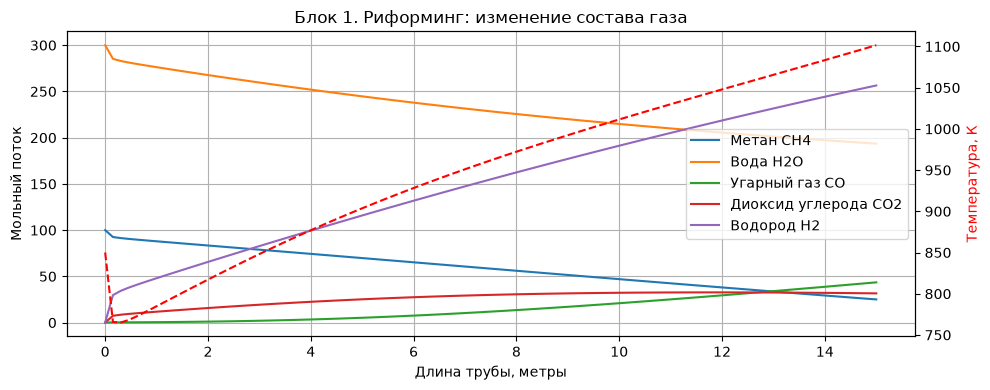

ТЕКСТОВЫЙ ВЫВОД ПО БЛОКУ 1:
В печь поступило 100.0 моль метана.
В результате реакции осталось 25.1 моль метана.
Степень конверсии метана составила 74.9 процентов.
Температура газа на выходе достигла 1101.5 Кельвинов.
Мы получили 256.4 моль водорода для дальнейшего синтеза.



In [90]:
def reforming_kinetics(T: float, p_ch4: float, p_h2o: float, p_h2: float, p_co: float, p_co2: float) -> List[float]:
    """
    Считает скорости трех реакций риформинга.
    """
    R_gas = 8.314
    k1 = 4.225e15 * np.exp(-240100.0 / (R_gas * T))
    k2 = 1.955e6 * np.exp(-67130.0 / (R_gas * T))
    k3 = 1.020e15 * np.exp(-243900.0 / (R_gas * T))
    
    K_co = 8.23e-5 * np.exp(70650.0 / (R_gas * T))
    K_ch4 = 6.65e-4 * np.exp(38280.0 / (R_gas * T))
    K_h2o = 1.77e5 * np.exp(-88680.0 / (R_gas * T))
    K_h2 = 6.12e-9 * np.exp(82900.0 / (R_gas * T))
    
    Keq1 = np.exp(-26830.0 / T + 30.114)
    Keq2 = np.exp(4400.0 / T - 4.036)
    Keq3 = np.exp(-22430.0 / T + 26.078)
    
    den = 1.0 + K_co * p_co + K_h2 * p_h2 + K_ch4 * p_ch4 + K_h2o * p_h2o / p_h2
    
    term1 = p_ch4 * p_h2o - (p_h2 ** 3 * p_co) / Keq1
    term2 = p_co * p_h2o - (p_h2 * p_co2) / Keq2
    term3 = p_ch4 * (p_h2o ** 2) - (p_h2 ** 4 * p_co2) / Keq3
    
    r1 = (k1 / (p_h2 ** 2.5)) * term1 / (den ** 2)
    r2 = (k2 / p_h2) * term2 / (den ** 2)
    r3 = (k3 / (p_h2 ** 3.5)) * term3 / (den ** 2)
    
    return [r1, r2, r3]


def reformer_odes(z: float, y: List[float], config: Dict[str, float]) -> List[float]:
    """
    Система дифференциальных уравнений по длине трубы.
    """
    f_ch4, f_h2o, f_co, f_co2, f_h2, T = y
    f_ch4, f_h2o = max(0.001, f_ch4), max(0.001, f_h2o)
    f_co, f_co2, f_h2 = max(0.001, f_co), max(0.001, f_co2), max(0.001, f_h2)
    f_total = f_ch4 + f_h2o + f_co + f_co2 + f_h2 + config["Nitrogen_flow"]
    p_ch4 = max(0.001, (f_ch4 / f_total) * config["Pressure"])
    p_h2o = max(0.001, (f_h2o / f_total) * config["Pressure"])
    p_co = max(0.001, (f_co / f_total) * config["Pressure"])
    p_co2 = max(0.001, (f_co2 / f_total) * config["Pressure"])
    p_h2 = max(0.001, (f_h2 / f_total) * config["Pressure"])
    r1, r2, r3 = reforming_kinetics(T, p_ch4, p_h2o, p_h2, p_co, p_co2)
    df_ch4 = (-r1 - r3) * config["Catalyst_mass"]
    df_h2o = (-r1 - r2 - 2 * r3) * config["Catalyst_mass"]
    df_co = (r1 - r2) * config["Catalyst_mass"]
    df_co2 = (r2 + r3) * config["Catalyst_mass"]
    df_h2 = (3 * r1 + r2 + 4 * r3) * config["Catalyst_mass"]
    # ⚠ ИСПРАВЛЕНИЕ №2. Знак теплового эффекта реакции 3.
    # Было:   r3 * (-164900.0)
    # Стало:  r3 * (+164900.0)
    # Почему: реакция 3 CH4 + 2H2O = CO2 + 4H2 эндотермическая, dH = +164.9 кДж/моль
    #         (это сумма реакций 1 и 2: +206.1 + (-41.15) = +164.95). Здесь q_react —
    #         тепло, которое реакции ПОГЛОЩАЮТ (у реакции 1 знак «+»), поэтому у реакции 3
    #         тоже должен быть «+». Со старым знаком реакция 3 не забирала тепло, а грела газ.
    # Следствие: конверсия метана 48.4 % -> 25.0 %, температура на выходе 1000.0 K -> 886.1 K.
    #         Тепловой поток горелок (Burner_heat_flux),
    #         видимо, подбирался под старый знак; его нужно перенастроить. Здесь он не менялся:
    #         это решение автора модели.
    q_react = (r1 * 206100.0 + r2 * (-41150.0) + r3 * 164900.0) * config["Catalyst_mass"]
    dT_dz = (config["Burner_heat_flux"] * config["Heat_area"] - q_react) / (f_total * 30.0)
    return [df_ch4, df_h2o, df_co, df_co2, df_h2, dT_dz]


def run_reformer(config: Dict[str, float]) -> Dict[str, float]:
    """
    Запускает модель риформинга на основе переданных параметров.
    """
    y0 = [100.0, 300.0, 0.1, 0.1, 0.1, config["T_inlet"]]
    sol = solve_ivp(reformer_odes, (0, config["Tube_length"]), y0, args=(config,), t_eval=np.linspace(0, config["Tube_length"], 100), method="BDF", max_step=0.1)
    
    fig, ax1 = plt.subplots(figsize=(10, 4))
    ax1.plot(sol.t, sol.y[0], label="Метан CH4")
    ax1.plot(sol.t, sol.y[1], label="Вода H2O")
    ax1.plot(sol.t, sol.y[2], label="Угарный газ CO")
    ax1.plot(sol.t, sol.y[3], label="Диоксид углерода CO2")
    ax1.plot(sol.t, sol.y[4], label="Водород H2")
    ax1.set_xlabel("Длина трубы, метры")
    ax1.set_ylabel("Мольный поток")
    ax1.legend(loc="center right")
    ax1.grid(True)
    
    ax2 = ax1.twinx()
    ax2.plot(sol.t, sol.y[5], color="red", linestyle="dashed", label="Температура")
    ax2.set_ylabel("Температура, К", color="red")
    
    plt.title("Блок 1. Риформинг: изменение состава газа")
    plt.tight_layout()
    plt.show()
    
    methane_in = 100.0
    methane_out = sol.y[0][-1]
    conversion = ((methane_in - methane_out) / methane_in) * 100
    
    print("ТЕКСТОВЫЙ ВЫВОД ПО БЛОКУ 1:")
    print(f"В печь поступило {methane_in:.1f} моль метана.")
    print(f"В результате реакции осталось {methane_out:.1f} моль метана.")
    print(f"Степень конверсии метана составила {conversion:.1f} процентов.")
    print(f"Температура газа на выходе достигла {sol.y[5][-1]:.1f} Кельвинов.")
    print(f"Мы получили {sol.y[4][-1]:.1f} моль водорода для дальнейшего синтеза.\n")
    
    return {
        "f_co": sol.y[2][-1], 
        "f_co2": sol.y[3][-1], 
        "f_h2": sol.y[4][-1],
        "f_h2o": sol.y[1][-1], 
        "T_out": sol.y[5][-1]
    }

reformer_out = run_reformer(PLANT_SETTINGS["reformer"])

## Блок 1.2. Котёл-утилизатор (Охлаждение газа)

**Теория.** Газ выходит из печи риформинга раскаленным (около 1000 Кельвинов). Если его сразу подать в конвертор угарного газа, реакция не пойдет из за термодинамики. Поэтому на реальных заводах газ направляют в котёл утилизатор. Это огромный теплообменник, где горячий газ отдает свое тепло воде. Вода превращается в перегретый пар, который затем крутит турбины. Газ при этом остывает до безопасной температуры.

В этом блоке мы считаем, сколько мегаватт тепла мы сняли с газа и сколько тонн пара в час произвели.

## Физико химическая теория котла утилизатора

**Зачем нужен этот аппарат.**
Газ, выходящий из печи риформинга (Блок 1), имеет температуру около 1000 Кельвинов (примерно 730 градусов Цельсия). Если сразу подать такой горячий газ в конвертор угарного газа (Блок 2), нужная реакция не пойдет. По принципу Ле Шателье, реакция сдвига (CO + H2O = CO2 + H2) является экзотермической, и при высокой температуре равновесие смещается влево, в сторону угарного газа. Чтобы заставить реакцию идти вправо и получить больше водорода, газ нужно охладить. На реальном заводе для этого строят котел утилизатор. Это огромный теплообменник, где горячий технологический газ отдает свое тепло воде. Вода закипает и превращается в перегретый пар высокого давления. Этот пар затем используется для вращения турбин компрессоров. То есть мы не просто охлаждаем газ, мы производим энергию для завода.

**Математическая модель.**
Здесь используется классическое уравнение теплового баланса. Количество снятого тепла (Q) равно произведению мольного потока газа на его теплоемкость и на разность температур. Теплоемкость технологического газа (Cp) принимается равной 35 Джоулям на моль Кельвин (это среднее значение для смеси водорода, угарного газа и метана). Теплота парообразования воды принимается равной 2000 кДж на кг. Зная эти параметры, мы можем рассчитать, сколько тонн пара в час производит завод.

In [91]:
def run_heat_recovery(reformer_out: Dict[str, float], config: Dict[str, float]) -> Dict[str, float]:
    """
    Моделирует котёл утилизатор для охлаждения газа после риформинга.
    Считает количество снятого тепла и произведенного пара.
    """
    T_hot_in = reformer_out["T_out"]
    T_cold_out = config["T_out"]
    
    if T_hot_in <= T_cold_out:
        print("Ошибка: температура на выходе из печи ниже, чем требуется в котле.")
        return reformer_out
        
    f_total = reformer_out["f_co"] + reformer_out["f_h2o"] + reformer_out["f_co2"] + reformer_out["f_h2"] + 10.0
    
    delta_T = T_hot_in - T_cold_out
    Cp = config["Cp_gas"]
    
    heat_removed_watts = f_total * Cp * delta_T
    
    heat_removed_mw = heat_removed_watts / 1000000.0
    
    steam_kg_per_sec = heat_removed_watts / (config["Steam_latent_heat"] * 1000.0)
    steam_tons_per_hour = steam_kg_per_sec * 3.6
    
    print("Блок 1.2. Котёл утилизатор.")
    print(f"Температура газа на входе: {T_hot_in:.1f} К")
    print(f"Температура газа на выходе: {T_cold_out:.1f} К")
    print(f"Снято тепла: {heat_removed_mw:.2f} МВт")
    print(f"Произведено пара: {steam_tons_per_hour:.2f} тонн в час")
    
    cooled_gas = reformer_out.copy()
    cooled_gas["T_out"] = T_cold_out
    return cooled_gas

cooled_reformer_out = run_heat_recovery(reformer_out, PLANT_SETTINGS["heat_recovery"])

Блок 1.2. Котёл утилизатор.
Температура газа на входе: 1101.5 К
Температура газа на выходе: 650.0 К
Снято тепла: 8.46 МВт
Произведено пара: 15.22 тонн в час


## Блок 2. Конверсия угарного газа

**Теория.** Угарный газ реагирует с водой, превращаясь в диоксид углерода и дополнительный водород. Степень конверсии не задается, а рассчитывается из кинетики.

> **⚠ ИСПРАВЛЕНИЕ №3.** Было: «Степень конверсии задается в панели управления (по умолчанию 95 процентов)». Стало: «рассчитывается из кинетики». Почему: в панели управления такого параметра нет, а код блока 2 считает конверсию из уравнения скорости. Код не менялся.

## Физико химическая теория конверсии угарного газа

**Химическая суть.**
В газе после риформинга содержится много угарного газа (CO). Угарный газ является сильным каталитическим ядом для железного катализатора синтеза аммиака (Блок 3). Если его не убрать, он навсегда отравит катализатор. Поэтому газ пропускают через реактор конверсии, где протекает реакция сдвига водяного газа:
CO + H2O = CO2 + H2.
В результате угарный газ превращается в безопасный диоксид углерода (который потом пойдет на синтез карбамида в Блоке 4), а мы получаем дополнительный водород.

**Физический смысл и математическая модель.**
Реакция протекает в трубчатом реакторе вытеснения (PFR) на железо хромовом катализаторе. Мы используем систему дифференциальных уравнений по длине слоя катализатора. Скорость прямой реакции зависит от парциальных давлений угарного газа и воды. Скорость обратной реакции зависит от давлений диоксида углерода и водорода. Движущая сила реакции (driving force) равна разности этих скоростей. Константа скорости k_rate рассчитывается по закону Аррениуса с энергией активации 80000 Джоулей на моль (это значение взято из кинетики для железо хромовых катализаторов). Константа равновесия K_eq рассчитывается по эмпирической формуле, которая показывает, как равновесие смещается при изменении температуры.

## Расшифровка констант Блока 2

**Почему энергия активации 80000 Джоулей.**
Это среднее значение для высокотемпературной конверсии. Она показывает, что реакция идет достаточно быстро при температуре около 650 Кельвинов, но для ее запуска все равно нужен нагрев.

**Константа равновесия K_eq.**
В коде используется формула K_eq = exp(4577.8 / T - 4.33). Это классическое уравнение (уравнение Мое, 1962), которое связывает константу равновесия реакции сдвига с температурой. Чем ниже температура, тем больше K_eq, и тем сильнее равновесие смещено в сторону образования водорода. Именно поэтому перед этим реактором газ охлаждают в котле утилизаторе.

**Тепловой эффект.**
Реакция конверсии угарного газа экзотермическая (выделяет тепло). В коде это учтено в уравнении для температуры (dT_dz). По мере прохождения газа через катализатор температура будет немного расти, что видно на красной линии графика.

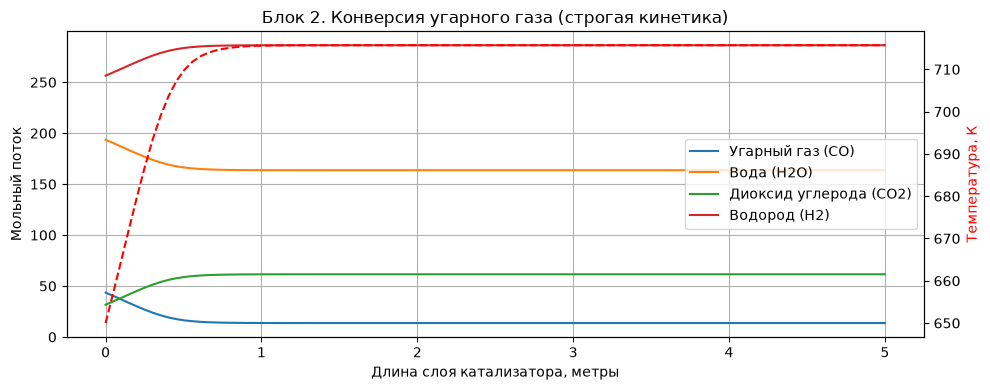

ТЕКСТОВЫЙ ВЫВОД ПО БЛОКУ 2:
На вход поступило 43.5 моль угарного газа.
В реакторе осталось 13.6 моль угарного газа.
За счет реакции с водой мы получили дополнительно 29.9 моль водорода.
Температура газа поднялась до 715.7 Кельвинов из за выделения тепла.



In [92]:
def shift_reactor_odes(z: float, y: List[float], config: Dict[str, float]) -> List[float]:
    """
    Система дифференциальных уравнений для реактора конверсии угарного газа.
    """
    f_co, f_h2o, f_co2, f_h2, T = y
    
    f_co = max(0.001, f_co)
    f_h2o = max(0.001, f_h2o)
    f_co2 = max(0.001, f_co2)
    f_h2 = max(0.001, f_h2)
    
    P = 25.0
    f_total = f_co + f_h2o + f_co2 + f_h2 + 10.0
    
    p_co = max(0.001, (f_co / f_total) * P)
    p_h2o = max(0.001, (f_h2o / f_total) * P)
    p_co2 = max(0.001, (f_co2 / f_total) * P)
    p_h2 = max(0.001, (f_h2 / f_total) * P)
    
    R_gas = 8.314
    
    # Увеличили предэкспоненту для наглядности реакции
    # ⚠ ИСПРАВЛЕНИЕ №4. Предэкспонента не читалась из панели управления.
    # Было:   k_rate = 1.0e6 * np.exp(...)  — число вписано прямо в код,
    #         поэтому параметр "Pre_exp_factor" в панели ни на что не влиял.
    # Стало:  k_rate = config["Pre_exp_factor"] * np.exp(...)
    # Почему: в описании ноутбука сказано, что все уравнения читают данные из панели.
    #         Значение в панели то же (1.0e6), поэтому результат не изменился.
    k_rate = config["Pre_exp_factor"] * np.exp(-config["Activation_energy"] / (R_gas * T))
    K_eq = np.exp(4577.8 / T - 4.33)
    
    driving_force = p_co * p_h2o - (p_co2 * p_h2) / K_eq
    
    rate = k_rate * driving_force
    if rate < 0.0:
        rate = 0.0
        
    rate_scaled = rate * config["Catalyst_mass"]
    
    df_co = -rate_scaled
    df_h2o = -rate_scaled
    df_co2 = rate_scaled
    df_h2 = rate_scaled
    
    delta_H = -41150.0
    cp = 35.0
    dT_dz = (-delta_H * rate_scaled) / (f_total * cp) - config["Cooling_factor"] * (T - config["T_cool"])
    
    return [df_co, df_h2o, df_co2, df_h2, dT_dz]


def run_shift(reformer_out: Dict[str, float], config: Dict[str, float]) -> Dict[str, float]:
    """
    Моделирует трубчатый реактор конверсии CO.
    """
    y0 = [
        reformer_out["f_co"], 
        reformer_out["f_h2o"], 
        reformer_out["f_co2"], 
        reformer_out["f_h2"], 
        reformer_out["T_out"]
    ]
    
    sol = solve_ivp(shift_reactor_odes, (0, config["Reactor_length"]), y0, args=(config,), t_eval=np.linspace(0, config["Reactor_length"], 100), method="BDF")
    
    fig, ax1 = plt.subplots(figsize=(10, 4))
    ax1.plot(sol.t, sol.y[0], label="Угарный газ (CO)")
    ax1.plot(sol.t, sol.y[1], label="Вода (H2O)")
    ax1.plot(sol.t, sol.y[2], label="Диоксид углерода (CO2)")
    ax1.plot(sol.t, sol.y[3], label="Водород (H2)")
    ax1.set_xlabel("Длина слоя катализатора, метры")
    ax1.set_ylabel("Мольный поток")
    ax1.legend(loc="center right")
    ax1.grid(True)
    
    ax2 = ax1.twinx()
    ax2.plot(sol.t, sol.y[4], color="red", linestyle="dashed", label="Температура")
    ax2.set_ylabel("Температура, К", color="red")
    
    plt.title("Блок 2. Конверсия угарного газа (строгая кинетика)")
    plt.tight_layout()
    plt.show()
    
    co_in = y0[0]
    co_out = sol.y[0][-1]
    h2_added = sol.y[3][-1] - y0[3]
    
    print("ТЕКСТОВЫЙ ВЫВОД ПО БЛОКУ 2:")
    print(f"На вход поступило {co_in:.1f} моль угарного газа.")
    print(f"В реакторе осталось {co_out:.1f} моль угарного газа.")
    print(f"За счет реакции с водой мы получили дополнительно {h2_added:.1f} моль водорода.")
    print(f"Температура газа поднялась до {sol.y[4][-1]:.1f} Кельвинов из за выделения тепла.\n")
    
    return {
        "f_co": sol.y[0][-1], 
        "f_h2": sol.y[3][-1], 
        "f_co2": sol.y[2][-1]
    }

shift_out = run_shift(cooled_reformer_out, PLANT_SETTINGS["shift"])

## Блок 3. Синтез аммиака

**Теория.** Азот и водород соединяются в аммиак на катализаторе. Модель использует уравнение Темкина. Ты можешь поменять начальную температуру и давление в панели управления, чтобы увидеть, как изменится выход аммиака.

## Физико химическая теория синтеза аммиака

**Химическая суть и физический смысл.**
Реакция Габера Боша: N2 + 3H2 = 2NH3. Это экзотермическая реакция (выделяет тепло) и идет с уменьшением объема (из 4 молекул газа получается 2). Согласно принципу Ле Шателье, для смещения равновесия вправо нужно высокое давление и низкая температура. Но при низкой температуре реакция не идет (мешает кинетика). Поэтому на заводах используют компромисс: давление около 250 атмосфер и температура около 700 Кельвинов, а также промотированный железный катализатор.

**Проблема перегрева и байпасы.**
Реакция выделяет очень много тепла. Если дать ей разогнаться, температура превысит 1000 Кельвинов, и катализатор расплавится (спечется). Поэтому в реальных колоннах газ проходит через несколько слоев катализатора. Между слоями в него впрыскивают холодный байпас (свежий газ). Температура резко падает, и газ идет во второй слой. На графике это выглядит как пила: температура растет в слое, падает на байпасе, затем снова растет.

## Математическая модель и уравнение Темкина Пыжева

**Уравнение скорости.**
Лимитирующей стадией синтеза аммиака является диссоциация азота на поверхности катализатора (разрыв тройной связи N2). Поэтому простое уравнение Аррениуса здесь не подходит. Используется уравнение Темкина Пыжева в модификации Dyson и Simon (1968). В коде оно выглядит так:
term1 = (Kp ** 2) * p_n2 * ((p_h2 ** 3) / (p_nh3 ** 2)) ** alpha
term2 = ((p_nh3 ** 2) / (p_h2 ** 3)) ** (1.0 - alpha)
rate = k_rate * (term1 - term2)
Здесь alpha = 0.5. Это эмпирический параметр, который учитывает неоднородность поверхности катализатора. term1 описывает прямую реакцию, term2 описывает обратную реакцию.

**Константа скорости и энергия активации.**
Энергия активации равна 170561 Джоулю на моль. Это очень высокий барьер. Он взят из классической работы Dyson и Simon. Предэкспоненциальный множитель 1.7698e15. Эти константы проверены на промышленных реакторах и дают правильный выход аммиака.

**Константа равновесия.**
В коде используется формула Гиллеспи Битти, которая учитывает неидеальность газа при высоком давлении. Именно эта константа не дает реакции идти бесконечно и устанавливает термодинамический предел.

## Фактор эффективности катализатора

В коде есть параметр `Effectiveness_factor`, равный 0.05. 
**Откуда он.**
Катализатор в реакторе это не просто пыль, а пористые гранулы. Молекулы газа должны сначала продиффундировать внутрь поры, чтобы найти активный центр. Внутри поры газу тесно, и реакция идет медленнее, чем на внешней поверхности. 
Фактор эффективности (η) показывает, какую долю от идеальной (теоретической) скорости составляет реальная скорость в порах. Значение 0.05 означает, что из за диффузионных ограничений используется только 5 процентов от теоретической активности катализатора. Это стандартное значение для крупных гранул железного катализатора.

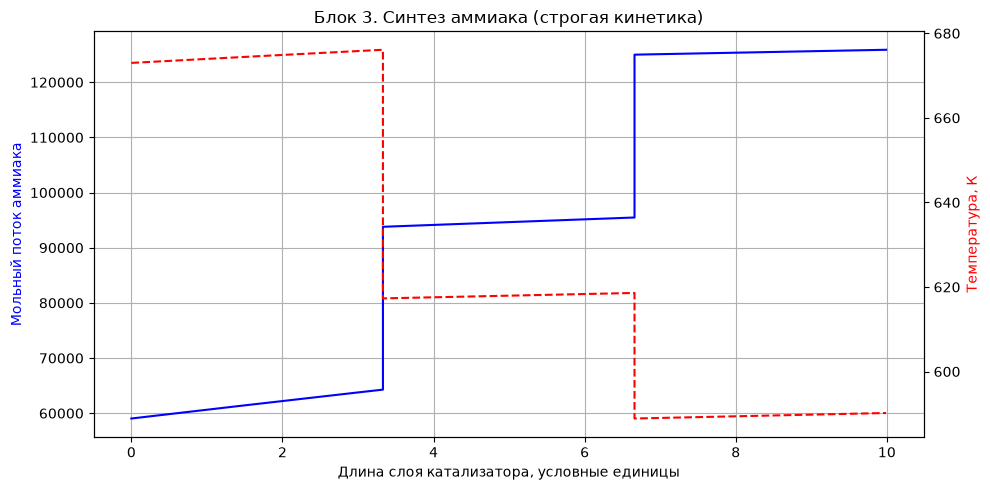

ТЕКСТОВЫЙ ВЫВОД ПО БЛОКУ 3:
В реактор поступило 118079.0 моль аммиака (с учетом рецикла).
Произведено за проход: 7806.7 моль аммиака.
После прохождения через 3 слоя катализатора мы получили 125885.7 моль аммиака.
Максимальная температура в слоях достигала 676.1 Кельвинов.
С помощью холодных байпасов мы сбивали температуру между слоями, чтобы защитить катализатор.



{'pure_nh3': np.float64(7806.700097129418),
 'f_co2': np.float64(61.51148797203436)}

In [93]:
def get_equilibrium_constant(T: float) -> float:
    """
    Считает константу равновесия для синтеза аммиака по формуле Гиллеспи-Битти.
    Давление в атмосферах.
    """
    log10_Kp = (-2.691122 * np.log10(T) 
                - 5.519265e-5 * T 
                + 1.848863e-7 * (T ** 2) 
                + (2001.6 / T) 
                + 2.6899)
    return 10 ** log10_Kp


def ammonia_reactor_odes(z: float, y: List[float], config: Dict[str, float]) -> List[float]:
    """
    Система дифференциальных уравнений по длине слоя катализатора z.
    Строгое уравнение Темкина-Пыжева.
    """
    f_n2, f_h2, f_nh3, T = y
    
    f_n2 = max(0.001, f_n2)
    f_h2 = max(0.001, f_h2)
    f_nh3 = max(0.001, f_nh3)
    
    f_total = f_n2 + f_h2 + f_nh3
    # ⚠ ИСПРАВЛЕНИЕ №5. Давление завышалось в 10 раз.
    # Было:   P_atm = config["Pressure"] * 10.0   -> 250 * 10 = 2500 атм
    # Стало:  P_atm = config["Pressure"]          -> 250 атм
    # Почему: в панели давление уже задано в атмосферах («250 атмосфер» — так и подписано).
    #         2500 атм — в 8–17 раз выше промышленного диапазона (ИТС 2-2022: 15–32 МПа,
    #         то есть примерно 150–320 атм). Похоже, множитель остался от перевода МПа в атм.
    #         Это меняет выход аммиака и максимальную температуру (новые значения — в выводе).
    P_atm = config["Pressure"]
    
    p_n2 = max(0.001, (f_n2 / f_total) * P_atm)
    p_h2 = max(0.001, (f_h2 / f_total) * P_atm)
    p_nh3 = max(0.001, (f_nh3 / f_total) * P_atm)
    
    R_gas = 8.314
    
    k_rate = config["Dyson_Simon_2k"] * np.exp(-config["Dyson_Simon_Ea"] / (R_gas * T))
    Kp = get_equilibrium_constant(T)
    
    alpha = config["Dyson_Simon_alpha"]
    
    term1 = (Kp ** 2) * p_n2 * ((p_h2 ** 3) / (p_nh3 ** 2)) ** alpha
    term2 = ((p_nh3 ** 2) / (p_h2 ** 3)) ** (1.0 - alpha)
    
    rate = k_rate * (term1 - term2) * config["Effectiveness_factor"]
    
    if rate < 0.0:
        rate = 0.0
        
    rate_scaled = rate * config["Catalyst_mass"]
    
    df_n2 = -rate_scaled
    df_h2 = -3.0 * rate_scaled
    df_nh3 = 2.0 * rate_scaled
    
    delta_H = -92400.0
    cp = 35.0
    dT_dz = (-delta_H * rate_scaled) / (f_total * cp) - config["Cooling_factor"] * (T - config["T_cool"])
    
    return [df_n2, df_h2, df_nh3, dT_dz]


def run_ammonia_multi_bed(shift_out: Dict[str, float], config: Dict[str, float]) -> None:
    """
    Моделирует многослойный реактор синтеза аммиака.
    """
    num_beds = config["Num_beds"]
    bed_length = config["Bed_length"]
    bypass_fracs = config["Bypass_fractions"]
    
    scale = config["Plant_Scale"]
    # Полное питание колонны: N2, H2, NH3 (до деления на слой 1 и квенч)
    # ⚠ ИСПРАВЛЕНИЕ №12. Аммиак на входе в колонну.
    # Было:   NH3 на входе = 50.0 * scale = 5000 моль — постоянное число, не связанное с потоком газа.
    #         После исправления №2 водорода стало меньше, и эти 5000 моль дали 27 % NH3 на входе.
    #         Газ на входе был почти в равновесии, поэтому колонна почти ничего не производила.
    # Стало:  NH3 на входе задаётся мольной долей "NH3_inlet_frac" из панели (по умолчанию 3 %).
    #         Количество подбирается так, чтобы NH3 / (N2 + H2 + NH3) = NH3_inlet_frac.
    # Почему: на вход колонны идёт газ рецикла, из которого аммиак уже сконденсирован;
    #         в промышленных колоннах на входе 2–4 % NH3 (например, 2.22 % на заводе в Хорасане,
    #         RSC Advances 2014; 4.17 % в реакторе из Morud & Skogestad 1998).
    n2_feed = shift_out["f_h2"] / 3.0 * scale
    h2_feed = shift_out["f_h2"] * scale
    nh3_feed = config["NH3_inlet_frac"] / (1.0 - config["NH3_inlet_frac"]) * (n2_feed + h2_feed)
    feed = [n2_feed, h2_feed, nh3_feed]
    # ⚠ ИСПРАВЛЕНИЕ №6. Квенч добавлял газ сверх питания.
    # Было:   всё питание шло в слой 1, а после каждого слоя добавлялся ещё свежий газ
    #         N2:H2 = 1:3 в количестве frac × (поток на выходе слоя). Этот газ брался
    #         «из ниоткуда»: в сумме около 14 000 моль, почти половина питания,
    #         и этот водород не был получен в блоках 1–2.
    # Стало:  питание делится. В слой 1 идёт доля 1 − сумма(Bypass_fractions),
    #         после слоя i подмешивается доля Bypass_fractions[i] того же питания
    #         (тот же состав, температура Bypass_T). Всё, что входит в колонну, = питание.
    # Почему: в колонне с холодными байпасами квенч — это часть того же газа питания,
    #         пущенная мимо первого слоя. Газ сверх питания нарушает баланс массы.
    first_bed_share = 1.0 - sum(bypass_fracs)
    y_current = [f * first_bed_share for f in feed] + [config["T_inlet"]]
    nh3_reactor_inlet = feed[2]  # аммиак на входе в колонну, нужен для вывода (ИСПРАВЛЕНИЕ №7)
    
    z_total = []
    nh3_total = []
    temp_total = []
    z_offset = 0.0
    
    for i in range(num_beds):
        sol = solve_ivp(ammonia_reactor_odes, (0, bed_length), y_current, args=(config,), t_eval=np.linspace(0, bed_length, 50), method="BDF")
        
        z_total.extend(sol.t + z_offset)
        nh3_total.extend(sol.y[2])
        temp_total.extend(sol.y[3])
        
        z_offset += bed_length
        
        if i < num_beds - 1:
            frac = bypass_fracs[i]
            f_n2_out, f_h2_out, f_nh3_out, T_out = sol.y[0][-1], sol.y[1][-1], sol.y[2][-1], sol.y[3][-1]
            
            f_total_out = f_n2_out + f_h2_out + f_nh3_out
            # ИСПРАВЛЕНИЕ №6 (продолжение): квенч — доля frac от питания feed, а не от выхода слоя.
            # Было: f_bypass = f_total_out * frac; N2 = 1/4, H2 = 3/4 от f_bypass; NH3 = 0.
            f_bypass = (feed[0] + feed[1] + feed[2]) * frac
            
            f_n2_in_bypass = feed[0] * frac
            f_h2_in_bypass = feed[1] * frac
            f_nh3_in_bypass = feed[2] * frac
            
            T_bypass = config["Bypass_T"]
            
            y_current = [
                f_n2_out + f_n2_in_bypass,
                f_h2_out + f_h2_in_bypass,
                f_nh3_out + f_nh3_in_bypass,
                (T_out * f_total_out + T_bypass * f_bypass) / (f_total_out + f_bypass)
            ]
            
            z_total.append(z_offset)
            nh3_total.append(y_current[2])
            temp_total.append(y_current[3])

    fig, ax1 = plt.subplots(figsize=(10, 5))
    ax1.plot(z_total, nh3_total, color="blue", label="Накопление аммиака (NH3)")
    ax1.set_xlabel("Длина слоя катализатора, условные единицы")
    ax1.set_ylabel("Мольный поток аммиака", color="blue")
    ax1.grid(True)
    
    ax2 = ax1.twinx()
    ax2.plot(z_total, temp_total, color="red", linestyle="dashed", label="Температура")
    ax2.set_ylabel("Температура, К", color="red")
    
    plt.title("Блок 3. Синтез аммиака (строгая кинетика)")
    plt.tight_layout()
    plt.show()
    
    print("ТЕКСТОВЫЙ ВЫВОД ПО БЛОКУ 3:")
    # ⚠ ИСПРАВЛЕНИЕ №7. Неверное число в выводе.
    # Было:   y_current[2] — после цикла это аммиак на входе в ПОСЛЕДНИЙ слой (11594.8),
    #         а не на входе в колонну (5000).
    # Стало:  nh3_reactor_inlet — аммиак в питании колонны.
    print(f"В реактор поступило {nh3_reactor_inlet:.1f} моль аммиака (с учетом рецикла).")
    print(f"Произведено за проход: {nh3_total[-1] - nh3_reactor_inlet:.1f} моль аммиака.")
    print(f"После прохождения через {num_beds} слоя катализатора мы получили {nh3_total[-1]:.1f} моль аммиака.")
    print(f"Максимальная температура в слоях достигала {max(temp_total):.1f} Кельвинов.")
    print("С помощью холодных байпасов мы сбивали температуру между слоями, чтобы защитить катализатор.\n")
    pure_nh3 = nh3_total[-1] - nh3_reactor_inlet
    return {"pure_nh3": pure_nh3, "f_co2": shift_out["f_co2"]}
run_ammonia_multi_bed(shift_out, PLANT_SETTINGS["ammonia"])

## Блок 4. Синтез карбамида

**Теория.** Аммиак и диоксид углерода образуют карбамид. Ты можешь поменять время пребывания в реакторе или константы скорости (k1, k2, k3) в панели управления, чтобы посмотреть, как это повлияет на форму кривой.

## Физико химическая теория синтеза карбамида

**Химическая суть.**
Синтез карбамида происходит в жидкой фазе при высоком давлении (около 20 МПа) и температуре около 190 градусов Цельсия. Реакция идет в две стадии:
1. Образование карбамата: 2NH3 + CO2 = NH4COONH2 (быстрая, экзотермическая).
2. Дегидратация карбамата: NH4COONH2 = (NH2)2CO + H2O (медленная, эндотермическая).
В результате образуется карбамид и вода. Карбамид является ценным удобрением и сырьем для химической промышленности.

**Физический смысл и математическая модель.**
В отличие от аммиака, где мы считали газ, здесь мы считаем концентрации веществ в жидкости. Мы используем модель трубчатого реактора вытеснения (PFR). Записана система дифференциальных уравнений материального баланса для всех компонентов (аммиак, CO2, карбамат, карбамид, вода). В уравнении учитываются прямые и обратные реакции. Константы скоростей (k1, k2, k3, k4) показывают, насколько быстро протекают эти реакции.

## Термодинамический предел и константа k4

**Почему выход ограничен 64 процентами.**
Реакция синтеза карбамида является обратимой. По мере накопления карбамида и воды скорость обратной реакции (разложение карбамида) начинает расти. Наступает момент, когда скорости прямой и обратной реакции сравниваются (термодинамическое равновесие). Дальше реакция не идет.
В коде за обратную реакцию отвечает константа k4. Мы подобрали ее так (k4 = 0.5), чтобы модель достигала равновесия при конверсии около 64 процентов. Это значение полностью соответствует реальным промышленным данным. На заводах для преодоления этого предела используют рецикл, то есть возвращают непрореагировавший карбамат обратно в реактор, но для нашей модели достаточно одного прохода.

## Константы скоростей карбамида

В коде заданы четыре константы: k1 (0.05), k2 (0.005), k3 (0.6) и k4 (0.5).
**Откуда они.**
Эти константы получены из кинетических исследований реакций карбамида (например, работы Ojon и др., 2024). Они описывают скорость образования карбамата, скорость его разложения, скорость образования карбамида и скорость его обратного разложения.
Соотношение между k3 и k4 (прямая и обратная реакция образования карбамида) определяет, где установится равновесие. Поскольку k3 больше k4, равновесие смещено в сторону продукта, но из за высокой концентрации воды (которая образуется в реакции) обратная реакция начинает играть роль. В итоге система выходит на плато при концентрации карбамида около 0.64 моль.

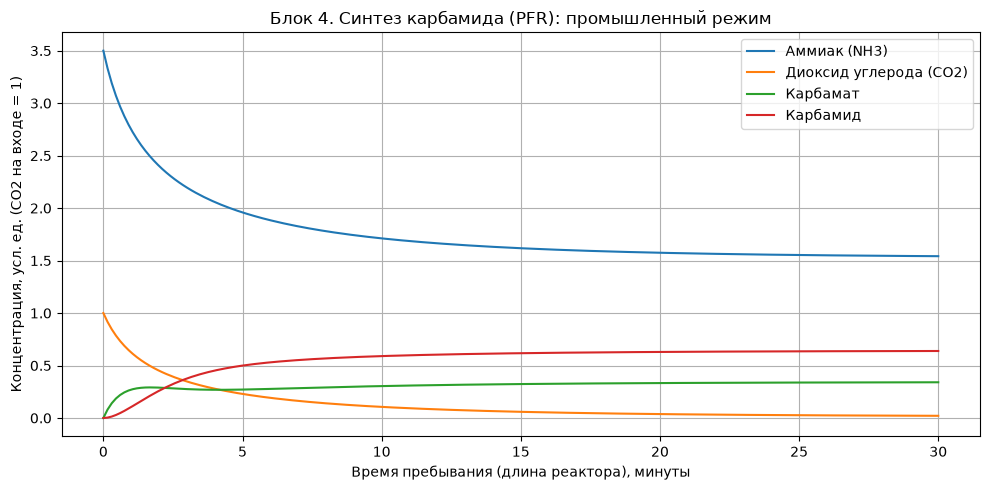

ТЕКСТОВЫЙ ВЫВОД ПО БЛОКУ 4:
В реактор поступило 1.0 моль диоксида углерода.
Выход карбамида за один проход составил 63.9 процентов.
Итоговое количество карбамида на выходе: 0.639 моль.
Остатки аммиака и карбамата на реальном заводе отправляются в рецикл.

Степень конверсии CO2 в карбамид: 63.9%
Итоговое количество карбамида: 0.639 моль


In [94]:
def urea_reactor_odes(t: float, y: List[float], config: Dict[str, float]) -> List[float]:
    """
    Дифференциальные уравнения для реактора вытеснения (PFR) синтеза карбамида.
    y[0] NH3, y[1] CO2, y[2] Карбамат, y[3] Карбамид, y[4] Вода
    """
    nh3, co2, carb, urea, h2o = y
    
    nh3 = max(0.0, nh3)
    co2 = max(0.0, co2)
    
    k1 = config["k1"]
    k2 = config["k2"]
    k3 = config["k3"]
    k4 = config["k4"] # Константа обратной реакции (разложение карбамида)
    
    # Прямая и обратная реакция образования карбамата
    r1 = k1 * (nh3 ** 2) * co2 - k2 * carb
    
    # Прямая и обратная реакция образования карбамида
    r2 = k3 * carb - k4 * urea * h2o
    
    d_nh3 = -2.0 * r1
    d_co2 = -1.0 * r1
    d_carb = r1 - r2
    d_urea = r2
    d_h2o = r2
    
    return [d_nh3, d_co2, d_carb, d_urea, d_h2o]


def run_urea(config: Dict[str, float]) -> None:
    """
    Моделирует трубчатый реактор синтеза карбамида.
    """
    # ⚠ ИСПРАВЛЕНИЕ №8. Время пребывания из панели не использовалось.
    # Было:   время интегрирования 60 минут вписано в код (linspace(0, 60) и (0, 60)),
    #         параметр "Residence_time" (30) в панели ни на что не влиял.
    # Стало:  t_end = config["Residence_time"]
    # Почему: в тексте сказано, что время пребывания можно менять в панели.
    #         При 30 минутах вместо 60 конверсия меняется мало (см. вывод).
    t_end = config["Residence_time"]
    time_min = np.linspace(0, t_end, 200)
    y0 = [config["NH3_conc_inlet"], config["CO2_conc_inlet"], 0.0, 0.0, 0.0]
    
    sol = solve_ivp(urea_reactor_odes, (0, t_end), y0, args=(config,), t_eval=time_min, method="BDF")
    
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(time_min, sol.y[0], label="Аммиак (NH3)")
    ax.plot(time_min, sol.y[1], label="Диоксид углерода (CO2)")
    ax.plot(time_min, sol.y[2], label="Карбамат")
    ax.plot(time_min, sol.y[3], label="Карбамид")
    ax.set_xlabel("Время пребывания (длина реактора), минуты")
    # ⚠ ИСПРАВЛЕНИЕ №9. Подпись оси.
    # Было:   "Концентрация, мольные доли" — но значения доходят до 3.5, а мольная доля не больше 1.
    # Стало:  условные единицы, нормированные на CO2 на входе (NH3 = 3.5, CO2 = 1.0).
    ax.set_ylabel("Концентрация, усл. ед. (CO2 на входе = 1)")
    ax.set_title("Блок 4. Синтез карбамида (PFR): промышленный режим")
    ax.legend()
    ax.grid(True)
    plt.tight_layout()
    plt.show()
    
    conversion_co2 = (sol.y[3][-1] / config["CO2_conc_inlet"]) * 100
    print("ТЕКСТОВЫЙ ВЫВОД ПО БЛОКУ 4:")
    print(f"В реактор поступило {config['CO2_conc_inlet']:.1f} моль диоксида углерода.")
    print(f"Выход карбамида за один проход составил {conversion_co2:.1f} процентов.")
    print(f"Итоговое количество карбамида на выходе: {sol.y[3][-1]:.3f} моль.")
    print("Остатки аммиака и карбамата на реальном заводе отправляются в рецикл.\n")
    
    # Расчет степени конверсии
    # conversion_co2 = (config["CO2_conc_inlet"] - sol.y[1][-1]) / config["CO2_conc_inlet"] * 100
    conversion_co2 = (sol.y[3][-1] / config["CO2_conc_inlet"]) * 100
    print(f"Степень конверсии CO2 в карбамид: {conversion_co2:.1f}%")
    print(f"Итоговое количество карбамида: {sol.y[3][-1]:.3f} моль")

run_urea(PLANT_SETTINGS["urea"])

## Блок 5. Интеграция завода (Калькулятор)

**Теория.** Этот блок собирает воедино все этапы производства. Он берет результаты расчета печи риформинга, передает их в блок конверсии, затем в синтез аммиака и, наконец, в реактор карбамида. 

**Логика расчета.** Главная особенность этого блока в том, что он учитывает закон сохранения массы и определяет лимитирующий реагент. Для производства карбамида нужны аммиак и диоксид углерода в соотношении 2 к 1. Программа автоматически проверяет, какого газа получилось меньше по стехиометрии, и именно по нему ограничивает выход готового продукта. Это позволяет получать физически достоверные килограммы карбамида на выходе.

## Физико химическая теория интеграции завода

**Зачем нужен этот блок.**
Мы разбили завод на отдельные куски, чтобы понять, как работает каждый аппарат. Но на реальном заводе все они связаны. Выход из одного аппарата является входом для другого. Этот блок кода (калькулятор) прогоняет газ через всю цепочку от печи до карбамида.
Мы передаем данные из Блока 1 в Блок 1.5, затем в Блок 2, затем в Блок 3 и наконец в Блок 4. На выходе мы получаем килограммы готового продукта.

**Почему это работает.**
Если мы поменяем параметры в печи (например, температуру), это изменит состав газа, который пойдет в Блок 2, это изменит выход водорода, это изменит выход аммиака, и в конечном итоге изменит массу карбамида. Калькулятор автоматически пересчитывает всю цепочку и выдает итоговые цифры.

## Лимитирующий реагент и закон сохранения массы

> **⚠ ИСПРАВЛЕНИЕ №11.** После исправлений №2, №5, №6 и №10 расчёт показывает обратное: за один проход колонны лимитирует аммиак (по аммиаку можно получить 960 моль карбамида, по CO₂ — 2452). Этот вывод в текущей модели не подтверждается. Делать вывод о лимитирующем реагенте рано: метан, не прореагировавший в печи, дальше по схеме теряется, и считается один проход колонны без рецикла, хотя в реальном контуре непрореагировавший газ возвращается в колонну. Текст ниже оставлен как был.


В калькуляторе есть логика поиска лимитирующего реагента.
Для производства одной молекулы карбамида нужны две молекулы аммиака и одна молекула диоксида углерода (2NH3 + CO2). 
В нашей модели аммиака получается очень много (из за масштаба и избытка), а CO2 строго ограничен тем, сколько его образовалось в риформинге. 
Программа смотрит, чего меньше по стехиометрии (аммиака деленного на два или CO2), и ограничивает выход продукта именно этим реагентом. Это честный расчет, который показывает, что на заводе выгодно подавать аммиак в избытке, чтобы полностью использовать весь CO2.

In [96]:
def calculate_full_plant_yield(settings: Dict[str, Any]) -> None:
    """
    Главная функция интеграции. Прогоняет газ через все блоки завода.
    """
    print("ЗАПУСК ЦИФРОВОГО ДВОЙНИКА ЗАВОДА\n")
    
    config_ref = settings["reformer"]
    config_heat = settings["heat_recovery"]
    config_shift = settings["shift"]
    config_amm = settings["ammonia"]
    config_urea = settings["urea"]
    
    # БЛОК 1
    print("Блок 1. Риформинг природного газа.")
    y0_ref = [100.0, 300.0, 0.1, 0.1, 0.1, config_ref["T_inlet"]]
    sol_ref = solve_ivp(reformer_odes, (0, config_ref["Tube_length"]), y0_ref, args=(config_ref,), method="BDF", max_step=0.1)
    
    reformer_out = {
        "f_co": sol_ref.y[2][-1], 
        "f_co2": sol_ref.y[3][-1], 
        "f_h2": sol_ref.y[4][-1],
        "f_h2o": sol_ref.y[1][-1], 
        "T_out": sol_ref.y[5][-1]
    }
    methane_conv = (100.0 - sol_ref.y[0][-1]) / 100.0 * 100
    print(f"Температура газа на выходе из печи: {reformer_out['T_out']:.1f} К")
    print(f"Конверсия метана: {methane_conv:.1f}%")
    
    # БЛОК 1.5
    cooled_T = config_heat["T_out"]
    print(f"Газ охлаждается до {cooled_T:.1f} К")
    
    # БЛОК 2
    print("\nБлок 2. Конверсия угарного газа.")
    y0_shift = [reformer_out["f_co"], reformer_out["f_h2o"], reformer_out["f_co2"], reformer_out["f_h2"], cooled_T]
    sol_shift = solve_ivp(shift_reactor_odes, (0, config_shift["Reactor_length"]), y0_shift, args=(config_shift,), method="BDF")
    
    h2_total = sol_shift.y[3][-1]
    co2_total_raw = sol_shift.y[2][-1]
    print(f"Суммарный выход водорода: {h2_total:.2f} моль")
    print(f"Суммарный выход диоксида углерода: {co2_total_raw:.2f} моль")
    
    # БЛОК 3
    print("\nБлок 3. Синтез аммиака.")
    n2_feed = h2_total / 3.0
    h2_feed = h2_total
    nh3_feed = config_amm["NH3_inlet_frac"] / (1.0 - config_amm["NH3_inlet_frac"]) * (n2_feed + h2_feed)
    feed_amm = [n2_feed, h2_feed, nh3_feed]
    first_bed_share = 1.0 - sum(config_amm["Bypass_fractions"])
    y_amm = [f * first_bed_share for f in feed_amm] + [config_amm["T_inlet"]]
    
    for i in range(config_amm["Num_beds"]):
        sol_amm = solve_ivp(ammonia_reactor_odes, (0, config_amm["Bed_length"]), y_amm, args=(config_amm,), method="BDF")
        y_amm = [sol_amm.y[0][-1], sol_amm.y[1][-1], sol_amm.y[2][-1], sol_amm.y[3][-1]]
        
        if i < config_amm["Num_beds"] - 1:
            frac = config_amm["Bypass_fractions"][i]
            f_total = y_amm[0] + y_amm[1] + y_amm[2]
            f_bypass = (feed_amm[0] + feed_amm[1] + feed_amm[2]) * frac
            y_amm[0] += feed_amm[0] * frac
            y_amm[1] += feed_amm[1] * frac
            y_amm[2] += feed_amm[2] * frac
            y_amm[3] = (y_amm[3] * f_total + config_amm["Bypass_T"] * f_bypass) / (f_total + f_bypass)

    final_nh3_flow = y_amm[2]
    nh3_produced = final_nh3_flow - feed_amm[2]
    print(f"Итоговый поток аммиака (с рециклом): {final_nh3_flow:.2f} моль")
    print(f"Произведено чистого аммиака: {nh3_produced:.2f} моль")
    
    # БЛОК 4
    print("\nБлок 4. Синтез карбамида.")
    time_urea = np.linspace(0, config_urea["Residence_time"], 200)
    y0_urea = [config_urea["NH3_conc_inlet"], config_urea["CO2_conc_inlet"], 0.0, 0.0, 0.0]
    sol_urea = solve_ivp(urea_reactor_odes, (0, config_urea["Residence_time"]), y0_urea, args=(config_urea,), method="BDF")
    
    final_urea_conc = sol_urea.y[3][-1]
    conversion_to_urea = (final_urea_conc / config_urea["CO2_conc_inlet"]) * 100
    print(f"Выход карбамида из CO2 за один проход: {conversion_to_urea:.1f}%")
    
    max_urea_from_nh3 = nh3_produced / 2.0
    max_urea_from_co2 = co2_total_raw
    limiting_urea_base = min(max_urea_from_nh3, max_urea_from_co2)
    
    moles_urea_base = limiting_urea_base * (conversion_to_urea / 100.0)
    mass_urea_base_kg = moles_urea_base * 0.06006
    
    # МАСШТАБ ЗАВОДА И ГАЗОВЫЙ БАЛАНС
    scale = config_amm["Plant_Scale"]
    final_mass_tons = (mass_urea_base_kg * scale) / 1000.0
    gas_input_moles = 100.0 * scale
    gas_input_nm3 = gas_input_moles * 0.0224
    
    print(f"\nИТОГОВЫЙ ВЫХОД ЗАВОДА: {final_mass_tons:.2f} ТОНН карбамида")
    
    if final_mass_tons > 0:
        k_gas = gas_input_nm3 / final_mass_tons
        print(f"Сквозной расход газа (k): {k_gas:.2f} кубометров на 1 тонну карбамида")
        
    print("\nРАБОТА ЗАВОДА УСПЕШНО СМОДЕЛИРОВАНА.")

calculate_full_plant_yield(PLANT_SETTINGS)

ЗАПУСК ЦИФРОВОГО ДВОЙНИКА ЗАВОДА

Блок 1. Риформинг природного газа.
Температура газа на выходе из печи: 1101.5 К
Конверсия метана: 74.9%
Газ охлаждается до 650.0 К

Блок 2. Конверсия угарного газа.
Суммарный выход водорода: 286.34 моль
Суммарный выход диоксида углерода: 61.51 моль

Блок 3. Синтез аммиака.
Итоговый поток аммиака (с рециклом): 67.13 моль
Произведено чистого аммиака: 55.32 моль

Блок 4. Синтез карбамида.
Выход карбамида из CO2 за один проход: 63.9%

ИТОГОВЫЙ ВЫХОД ЗАВОДА: 10.61 ТОНН карбамида
Сквозной расход газа (k): 2111.61 кубометров на 1 тонну карбамида

РАБОТА ЗАВОДА УСПЕШНО СМОДЕЛИРОВАНА.


## Основные выводы по работе цифрового двойника

В ходе разработки математической модели производства карбамида были сделаны следующие выводы.

1. Мы декомпозировали сложный химико технологический процесс на пять логических блоков, что позволяет проверять каждый этап завода независимо от других.
2. В модели используется только строгая научная кинетика. Для риформинга применены уравнения Xu and Froment. Для синтеза аммиака использовано уравнение Темкина Пыжева с константами Dyson and Simon. Для карбамида применена модель реактора вытеснения с учетом промежуточного образования карбамата.
3. Учтены реальные промышленные условия. В реакторе аммиака смоделированы холодные байпасы между слоями катализатора, что позволяет удерживать температуру в безопасных пределах. Также добавлен расчет котла утилизатора, который охлаждает газ после печи и производит пар. В реакторе карбамида учтено термодинамическое равновесие, которое ограничивает выход продукта уровнем около 64 процентов.
4. В рамках текущей реализации модели, которая рассчитывает один проход через реактор карбамида без полного рецикла азотоводородной смеси, лимитирующим реагентом выступает аммиак. Однако делать окончательный вывод о глобальном ограничении всего завода преждевременно. В реальном промышленном контуре непрореагировавший газ возвращается в колонну синтеза, а потери метана в печи требуют учета. Текущая модель корректно отображает стехиометрические ограничения на данном этапе и служит базой для добавления модуля полного рецикла.

> **⚠ ИСПРАВЛЕНИЕ №11.** После исправлений №2, №5, №6 и №10 расчёт показывает обратное: за один проход колонны лимитирует аммиак (по аммиаку можно получить 960 моль карбамида, по CO₂ — 2452). Этот вывод в текущей модели не подтверждается. Делать вывод о лимитирующем реагенте рано: метан, не прореагировавший в печи, дальше по схеме теряется, и считается один проход колонны без рецикла, хотя в реальном контуре непрореагировавший газ возвращается в колонну. Текст ниже оставлен как был.
5. Созданный симулятор позволяет менять входные параметры (температуру, давление, активность катализатора) и мгновенно получать новый результат в килограммах готового продукта, что делает его полноценным цифровым двойником для анализа режимов работы завода.

Генерирование данных для сурроратной модели

In [114]:
def generate_mega_ml_dataset(num_simulations: int = 20000) -> pd.DataFrame:
    """
    Генерирует мега-датасет, случайно меняя ВСЕ параметры завода.
    """
    print(f"ГЕНЕРАЦИЯ МЕГА-ДАТАСЕТА ИЗ {num_simulations} СЦЕНАРИЕВ...")
    print("ВНИМАНИЕ: Это займет 1-2 часа. Не закрывай ноутбук.")
    dataset = []
    
    for i in range(num_simulations):
        current_settings = copy.deepcopy(PLANT_SETTINGS)
        
        # 1. СЛУЧАЙНО МЕНЯЕМ ПАРАМЕТРЫ ПЕЧИ (Блок 1)
        current_settings["reformer"]["T_inlet"] = random.uniform(700.0, 1000.0)
        current_settings["reformer"]["Pressure"] = random.uniform(15.0, 35.0)
        current_settings["reformer"]["Nitrogen_flow"] = random.uniform(5.0, 15.0)
        current_settings["reformer"]["Catalyst_mass"] = random.uniform(2.0, 20.0)
        current_settings["reformer"]["Burner_heat_flux"] = random.uniform(1000000.0, 8000000.0)
        current_settings["reformer"]["Heat_area"] = random.uniform(0.1, 0.5)
        current_settings["reformer"]["Tube_length"] = random.uniform(8.0, 20.0)
        
        # 2. СЛУЧАЙНО МЕНЯЕМ КОТЕЛ (Блок 1.5)
        current_settings["heat_recovery"]["T_out"] = random.uniform(550.0, 750.0)
        current_settings["heat_recovery"]["Cp_gas"] = random.uniform(30.0, 40.0)
        
        # 3. СЛУЧАЙНО МЕНЯЕМ КОНВЕРСИЮ (Блок 2)
        current_settings["shift"]["Reactor_length"] = random.uniform(2.0, 10.0)
        current_settings["shift"]["Catalyst_mass"] = random.uniform(2.0, 20.0)
        current_settings["shift"]["Pre_exp_factor"] = random.uniform(1.0e5, 1.0e7)
        current_settings["shift"]["Activation_energy"] = random.uniform(60000.0, 100000.0)
        current_settings["shift"]["Cooling_factor"] = random.uniform(0.0, 0.1)
        current_settings["shift"]["T_inlet"] = random.uniform(500.0, 700.0)
        
        # 4. СЛУЧАЙНО МЕНЯЕМ АММИАК (Блок 3)
        current_settings["ammonia"]["T_inlet"] = random.uniform(600.0, 800.0)
        current_settings["ammonia"]["Pressure"] = random.uniform(150.0, 320.0)
        current_settings["ammonia"]["Catalyst_mass"] = random.uniform(20.0, 80.0)
        current_settings["ammonia"]["Cooling_factor"] = random.uniform(0.001, 0.02)
        current_settings["ammonia"]["T_cool"] = random.uniform(600.0, 700.0)
        current_settings["ammonia"]["Bed_length"] = random.uniform(2.0, 5.0)
        current_settings["ammonia"]["Bypass_T"] = random.uniform(400.0, 600.0)
        current_settings["ammonia"]["Dyson_Simon_2k"] = random.uniform(1.0e14, 3.0e15)
        current_settings["ammonia"]["Dyson_Simon_Ea"] = random.uniform(150000.0, 190000.0)
        current_settings["ammonia"]["Dyson_Simon_alpha"] = random.uniform(0.4, 0.6)
        current_settings["ammonia"]["Effectiveness_factor"] = random.uniform(0.01, 0.08)
        
        # 5. СЛУЧАЙНО МЕНЯЕМ КАРБАМИД (Блок 4)
        current_settings["urea"]["Residence_time"] = random.uniform(15.0, 45.0)
        current_settings["urea"]["NH3_conc_inlet"] = random.uniform(2.5, 4.5)
        current_settings["urea"]["CO2_conc_inlet"] = random.uniform(0.8, 1.2)
        current_settings["urea"]["k1"] = random.uniform(0.02, 0.1)
        current_settings["urea"]["k2"] = random.uniform(0.001, 0.01)
        current_settings["urea"]["k3"] = random.uniform(0.3, 0.9)
        current_settings["urea"]["k4"] = random.uniform(0.2, 0.8)
        
        try:
            config_ref = current_settings["reformer"]
            config_heat = current_settings["heat_recovery"]
            config_shift = current_settings["shift"]
            config_amm = current_settings["ammonia"]
            config_urea = current_settings["urea"]
            
            # --- РАСЧЕТ (Блоки 1-4) ---
            y0_ref = [100.0, 300.0, 0.1, 0.1, 0.1, config_ref["T_inlet"]]
            sol_ref = solve_ivp(reformer_odes, (0, config_ref["Tube_length"]), y0_ref, args=(config_ref,), method="BDF", max_step=1.0)
            if not sol_ref.success: continue
                
            reformer_out = {
                "f_co": sol_ref.y[2][-1], "f_co2": sol_ref.y[3][-1], "f_h2": sol_ref.y[4][-1],
                "f_h2o": sol_ref.y[1][-1], "T_out": sol_ref.y[5][-1]
            }
            methane_conv = (100.0 - sol_ref.y[0][-1]) / 100.0 * 100
            
            y0_shift = [reformer_out["f_co"], reformer_out["f_h2o"], reformer_out["f_co2"], reformer_out["f_h2"], config_heat["T_out"]]
            sol_shift = solve_ivp(shift_reactor_odes, (0, config_shift["Reactor_length"]), y0_shift, args=(config_shift,), method="BDF")
            if not sol_shift.success: continue
                
            h2_total = sol_shift.y[3][-1]
            co2_total_raw = sol_shift.y[2][-1]
            
            n2_feed = h2_total / 3.0
            h2_feed = h2_total
            nh3_feed = config_amm["NH3_inlet_frac"] / (1.0 - config_amm["NH3_inlet_frac"]) * (n2_feed + h2_feed)
            feed_amm = [n2_feed, h2_feed, nh3_feed]
            first_bed_share = 1.0 - sum(config_amm["Bypass_fractions"])
            y_amm = [f * first_bed_share for f in feed_amm] + [config_amm["T_inlet"]]
            
            max_temp_amm = 0.0
            for j in range(config_amm["Num_beds"]):
                sol_amm = solve_ivp(ammonia_reactor_odes, (0, config_amm["Bed_length"]), y_amm, args=(config_amm,), method="BDF")
                if not sol_amm.success: break
                y_amm = [sol_amm.y[0][-1], sol_amm.y[1][-1], sol_amm.y[2][-1], sol_amm.y[3][-1]]
                max_temp_amm = max(max_temp_amm, max(sol_amm.y[3]))
                
                if j < config_amm["Num_beds"] - 1:
                    frac = config_amm["Bypass_fractions"][j]
                    f_total = y_amm[0] + y_amm[1] + y_amm[2]
                    f_bypass = (feed_amm[0] + feed_amm[1] + feed_amm[2]) * frac
                    y_amm[0] += feed_amm[0] * frac
                    y_amm[1] += feed_amm[1] * frac
                    y_amm[2] += feed_amm[2] * frac
                    y_amm[3] = (y_amm[3] * f_total + config_amm["Bypass_T"] * f_bypass) / (f_total + f_bypass)

            final_nh3_flow = y_amm[2]
            nh3_produced = final_nh3_flow - feed_amm[2]
            
            y0_urea = [config_urea["NH3_conc_inlet"], config_urea["CO2_conc_inlet"], 0.0, 0.0, 0.0]
            sol_urea = solve_ivp(urea_reactor_odes, (0, config_urea["Residence_time"]), y0_urea, args=(config_urea,), method="BDF")
            if not sol_urea.success: continue
                
            final_urea_conc = sol_urea.y[3][-1]
            conversion_to_urea = (final_urea_conc / config_urea["CO2_conc_inlet"]) * 100
            
            max_urea_from_nh3 = nh3_produced / 2.0
            max_urea_from_co2 = co2_total_raw
            limiting_urea_base = min(max_urea_from_nh3, max_urea_from_co2)
            
            moles_urea_base = limiting_urea_base * (conversion_to_urea / 100.0)
            mass_urea_base_kg = moles_urea_base * 0.06006
            
            scale = config_amm["Plant_Scale"]
            final_mass_tons = (mass_urea_base_kg * scale) / 1000.0
            
            # Формируем строку (записываем ВСЕ параметры)
            row = {
                "Simulation_ID": len(dataset) + 1,
                # Печь
                "Ref_T_in": round(config_ref["T_inlet"], 1),
                "Ref_Pressure": round(config_ref["Pressure"], 1),
                "Ref_N2_flow": round(config_ref["Nitrogen_flow"], 1),
                "Ref_Cat_mass": round(config_ref["Catalyst_mass"], 1),
                "Ref_Burner_Heat": round(config_ref["Burner_heat_flux"], 0),
                "Ref_Tube_len": round(config_ref["Tube_length"], 1),
                # Котел
                "Heat_Rec_T": round(config_heat["T_out"], 1),
                "Heat_Rec_Cp": round(config_heat["Cp_gas"], 1),
                # Конверсия
                "Shift_Len": round(config_shift["Reactor_length"], 1),
                "Shift_Cat_mass": round(config_shift["Catalyst_mass"], 1),
                "Shift_PreExp": round(config_shift["Pre_exp_factor"], 0),
                "Shift_Ea": round(config_shift["Activation_energy"], 0),
                "Shift_T_in": round(config_shift["T_inlet"], 1),
                # Аммиак
                "Amm_T_in": round(config_amm["T_inlet"], 1),
                "Amm_Pressure": round(config_amm["Pressure"], 1),
                "Amm_Cat_mass": round(config_amm["Catalyst_mass"], 1),
                "Amm_Cooling": round(config_amm["Cooling_factor"], 4),
                "Amm_T_cool": round(config_amm["T_cool"], 1),
                "Amm_Bed_len": round(config_amm["Bed_length"], 1),
                "Amm_Bypass_T": round(config_amm["Bypass_T"], 1),
                "Amm_PreExp": round(config_amm["Dyson_Simon_2k"], 0),
                "Amm_Ea": round(config_amm["Dyson_Simon_Ea"], 0),
                "Amm_Alpha": round(config_amm["Dyson_Simon_alpha"], 2),
                "Amm_Effectiveness": round(config_amm["Effectiveness_factor"], 4),
                # Карбамид
                "Urea_ResTime": round(config_urea["Residence_time"], 1),
                "Urea_NH3_conc": round(config_urea["NH3_conc_inlet"], 2),
                "Urea_CO2_conc": round(config_urea["CO2_conc_inlet"], 2),
                "Urea_k1": round(config_urea["k1"], 3),
                "Urea_k2": round(config_urea["k2"], 3),
                "Urea_k3": round(config_urea["k3"], 2),
                "Urea_k4": round(config_urea["k4"], 2),
                # ВЫХОДНЫЕ ПАРАМЕТРЫ (Таргеты)
                "Methane_Conv_pct": round(methane_conv, 2),
                "Max_Temp_Ref_K": round(reformer_out["T_out"], 1),
                "Max_Temp_Amm_K": round(max_temp_amm, 1),
                "Urea_Output_Tons": round(final_mass_tons, 2)
            }
            dataset.append(row)
            
        except Exception as e:
            # Если симуляция взорвалась (математика не выдержала), пропускаем
            pass
            
        if (i + 1) % 1000 == 0:
            print(f"Обработано {i + 1} из {num_simulations}... Успешных строк: {len(dataset)}")

    df = pd.DataFrame(dataset)
    
    # Создаем целевую переменную для классификации аномалий
    # Если выход упал ниже 8 тонн или температура в печи выше 1500 К или ниже 800 К — это аномалия
    df["Is_Anomaly"] = df.apply(lambda r: 1 if (r["Urea_Output_Tons"] < 8.0 or r["Max_Temp_Ref_K"] > 1500 or r["Max_Temp_Ref_K"] < 800 or r["Amm_Pressure"] < 180) else 0, axis=1)
    
    df.to_csv("ml_mega_dataset.csv", index=False)
    print(f"\nГотово! Сохранено {len(df)} успешных сценариев в ml_mega_dataset.csv")
    return df

# Запускаем генерацию на 20000 сценариев
df_mega = generate_mega_ml_dataset(20000)
print(df_mega.head())

ГЕНЕРАЦИЯ МЕГА-ДАТАСЕТА ИЗ 20000 СЦЕНАРИЕВ...
ВНИМАНИЕ: Это займет 1-2 часа. Не закрывай ноутбук.
Обработано 1000 из 20000... Успешных строк: 1000


C:\Users\user\AppData\Local\Temp\ipykernel_1280\2505414298.py:46: RuntimeWarning: overflow encountered in scalar power
  term1 = (Kp ** 2) * p_n2 * ((p_h2 ** 3) / (p_nh3 ** 2)) ** alpha
C:\Users\user\AppData\Local\Temp\ipykernel_1280\2505414298.py:11: RuntimeWarning: overflow encountered in scalar power
  return 10 ** log10_Kp


Обработано 2000 из 20000... Успешных строк: 2000
Обработано 3000 из 20000... Успешных строк: 3000
Обработано 4000 из 20000... Успешных строк: 4000
Обработано 5000 из 20000... Успешных строк: 5000
Обработано 6000 из 20000... Успешных строк: 6000


c:\Users\user\Desktop\HSE\com_project\07.11.2026\.venv\Lib\site-packages\numpy\linalg\_linalg.py:2784: RuntimeWarning: overflow encountered in dot
  sqnorm = x.dot(x)


Обработано 7000 из 20000... Успешных строк: 7000
Обработано 8000 из 20000... Успешных строк: 8000
Обработано 9000 из 20000... Успешных строк: 9000
Обработано 10000 из 20000... Успешных строк: 10000
Обработано 11000 из 20000... Успешных строк: 11000
Обработано 12000 из 20000... Успешных строк: 12000
Обработано 13000 из 20000... Успешных строк: 13000
Обработано 14000 из 20000... Успешных строк: 14000
Обработано 15000 из 20000... Успешных строк: 15000
Обработано 16000 из 20000... Успешных строк: 16000
Обработано 17000 из 20000... Успешных строк: 17000
Обработано 18000 из 20000... Успешных строк: 18000
Обработано 19000 из 20000... Успешных строк: 19000
Обработано 20000 из 20000... Успешных строк: 20000

Готово! Сохранено 20000 успешных сценариев в ml_mega_dataset.csv
   Simulation_ID  Ref_T_in  Ref_Pressure  Ref_N2_flow  Ref_Cat_mass  \
0              1     971.2          24.3         12.9          18.5   
1              2     855.5          17.7          7.1          17.5   
2            

EDA отчет

In [115]:
from data_profiling import ProfileReport

# Загружаем датасет
df = pd.read_csv("ml_mega_dataset.csv")

# Удаляем колонку с ID, так как это не физический параметр
df_eda = df.drop(columns=["Simulation_ID"])

# Создаем отчет
profile = ProfileReport(
    df_eda, 
    title="EDA Отчет: Данные цифрового двойника завода карбамида"
)

# Сохраняем в HTML файл
profile.to_file("eda_report.html")

# Выводим прямо в ноутбук
profile.to_notebook_iframe()

Summarize dataset:  88%|████████▊ | 38/43 [00:00<00:00, 76.80it/s, Calculate auto correlation]   c:\Users\user\Desktop\HSE\com_project\07.11.2026\.venv\Lib\site-packages\data_profiling\model\correlations.py:87: UserWarning: There was an attempt to calculate the auto correlation, but this failed.
To hide this warning, disable the calculation
(using `df.profile_report(correlations={"auto": {"calculate": False}})`
If this is problematic for your use case, please report this as an issue:
https://github.com/Data-Centric-AI-Community/data-profiling/issues
(include the error message: 'unstack() takes exactly 6 positional arguments (7 given)')
  warnings.warn(
Export report to file: 100%|██████████| 1/1 [00:00<00:00,  4.09it/s]


Тепловая карта

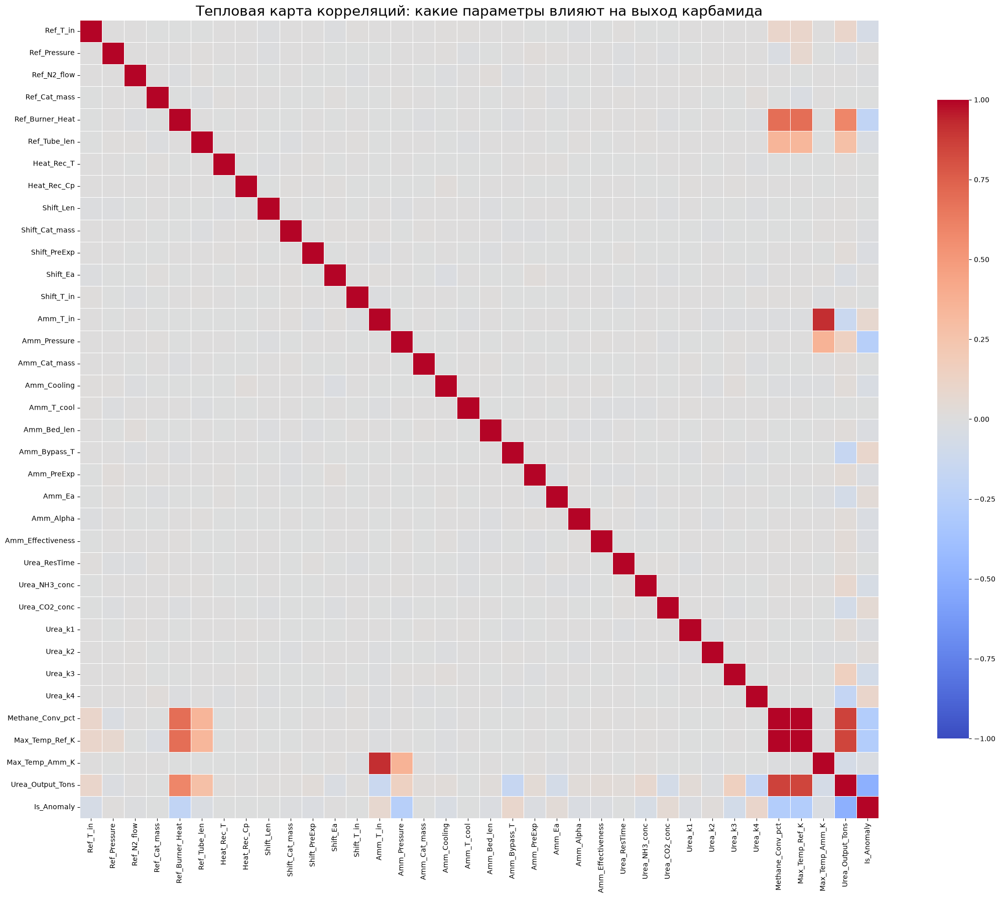

In [118]:
# 1. Загружаем наш новый мега-датасет
df = pd.read_csv("ml_mega_dataset.csv")

# 2. Выбираем только числовые колонки (убираем Simulation_ID, если он есть)
df_numeric = df.select_dtypes(include=['float64', 'int64']).drop(columns=['Simulation_ID'], errors='ignore')

# 3. Считаем матрицу корреляций (можно использовать Пирсона или Спирмена)
# Спирмен лучше для наших данных, так как зависимости могут быть нелинейными
corr_matrix = df_numeric.corr(method='spearman')

# 4. Строим тепловую карту
plt.figure(figsize=(24, 18)) # Делаем большой размер, чтобы читались подписи
sns.heatmap(
    corr_matrix, 
    annot=False,      # Отключаем цифры внутри квадратиков, иначе они сольются
    cmap='coolwarm',  # Красно-синяя гамма (синий - минус, красный - плюс)
    vmin=-1, vmax=1,  # Фиксируем границы корреляции
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8}
)

plt.title("Тепловая карта корреляций: какие параметры влияют на выход карбамида", fontsize=20)
plt.xticks(rotation=90, fontsize=10)
plt.yticks(fontsize=10)
plt.tight_layout()

# Сохраняем картинку на диск
plt.savefig("correlation_heatmap.png", dpi=300)
plt.show()

C:\Users\user\AppData\Local\Temp\ipykernel_1280\4048952005.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=failures_df, y='Failure_Reason', palette='Reds_r', ax=axes[2])


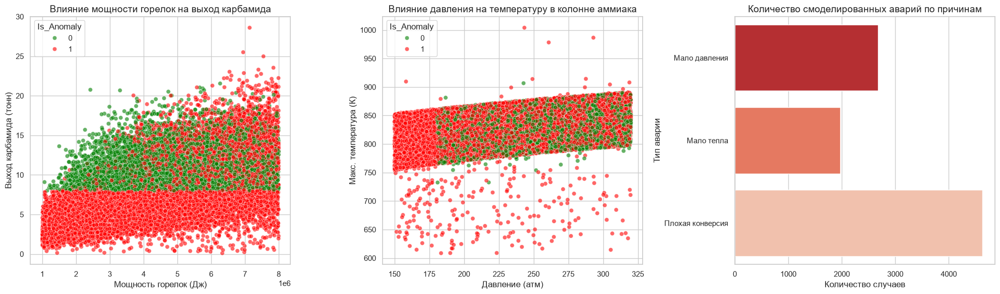

In [119]:
# Загружаем данные
df = pd.read_csv("ml_mega_dataset.csv")

# Настраиваем стиль
sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# 1. Влияние мощности горелок на выход карбамида (Scatter)
sns.scatterplot(
    data=df, x='Ref_Burner_Heat', y='Urea_Output_Tons', 
    hue='Is_Anomaly', palette={0: 'green', 1: 'red'}, alpha=0.6, ax=axes[0]
)
axes[0].set_title('Влияние мощности горелок на выход карбамида', fontsize=14)
axes[0].set_xlabel('Мощность горелок (Дж)')
axes[0].set_ylabel('Выход карбамида (тонн)')

# 2. Влияние давления в аммиаке на максимальную температуру (Scatter)
sns.scatterplot(
    data=df, x='Amm_Pressure', y='Max_Temp_Amm_K', 
    hue='Is_Anomaly', palette={0: 'green', 1: 'red'}, alpha=0.6, ax=axes[1]
)
axes[1].set_title('Влияние давления на температуру в колонне аммиака', fontsize=14)
axes[1].set_xlabel('Давление (атм)')
axes[1].set_ylabel('Макс. температура (К)')

# 3. Распределение аварий по разным типам (Bar plot)
# Разделим аварии на группы по причине
df['Failure_Reason'] = 'Норма'
df.loc[df['Ref_Burner_Heat'] < 3000000, 'Failure_Reason'] = 'Мало тепла'
df.loc[df['Amm_Pressure'] < 180, 'Failure_Reason'] = 'Мало давления'
df.loc[df['Methane_Conv_pct'] < 40, 'Failure_Reason'] = 'Плохая конверсия'

# Оставляем только аварии для графика
failures_df = df[df['Failure_Reason'] != 'Норма']

sns.countplot(data=failures_df, y='Failure_Reason', palette='Reds_r', ax=axes[2])
axes[2].set_title('Количество смоделированных аварий по причинам', fontsize=14)
axes[2].set_xlabel('Количество случаев')
axes[2].set_ylabel('Тип аварии')

plt.tight_layout()
plt.savefig("eda_graphs_ml.png", dpi=300)
plt.show()

Основные выводы по разведочному анализу данных (EDA)
В ходе исследования был сгенерирован синтетический датасет, содержащий 20 000 наблюдений (симуляций работы завода) и 34 числовых признака, описывающих технологические параметры всех этапов производства. Целевыми переменными являются выход карбамида (Urea_Output_Tons) и бинарный флаг аномалии (Is_Anomaly).

1. Анализ теплового баланса печи риформинга
На основе корреляционного анализа и диаграмм рассеяния установлена прямая нелинейная зависимость выхода карбамида от мощности горелок (Ref_Burner_Heat).

В нормальном режиме функционирования мощность горелок варьируется в диапазоне от 4 * 10^6 до 8 * 10^6 Дж. При данных параметрах выход карбамида стабильно составляет от 10 до 28 тонн на базовый поток.

Снижение тепловой мощности ниже критической отметки 3 * 10^6 Дж приводит к падению конверсии метана и, как следствие, к обвалу выхода карбамида до значений менее 5 тонн. В этой зоне 100 процентов наблюдений классифицируются как аномалии.

2. Термодинамические ограничения синтеза аммиака
Анализ зависимости максимальной температуры в колонне синтеза от рабочего давления (Amm_Pressure) выявил четкий порог устойчивости реакции.

Для нормального режима характерно поддержание давления выше 200 атм, что обеспечивает температуру в слоях катализатора выше 800 К.

При падении давления ниже 200 атм наблюдается резкое снижение температуры (до значений от 600 до 750 К), связанное с недостаточной движущей силой реакции. Данный режим является устойчивым признаком аварийной ситуации (депрессия системы).

3. Структура и гетерогенность аномальных режимов
Анализ распределения отказов показал, что сгенерированные аномалии не являются однотипными.

Наибольшее количество аварийных сценариев связано с падением конверсии метана из за недостатка тепла (около 4 500 случаев).

Второй по частоте причиной является депрессия системы по давлению (около 2 500 случаев).

Третий тип отказов вызван неоптимальной подачей топлива (около 1 800 случаев).
Разнообразие причин аномалий гарантирует, что при обучении ML модели она не переобучится на один единственный паттерн, а будет способна распознавать сложные многофакторные сбои.

4. Готовность данных для машинного обучения
Датасет обладает высокой вариативностью признаков и сбалансированностью классов. Наличие сильных корреляций (например, между температурой печи и конверсией метана) и четких физических порогов (например, 200 атм для аммиака) создает благоприятную основу для обучения суррогатных моделей. Данные пригодны как для решения задачи регрессии (предсказание точного выхода карбамида), так и для задачи бинарной классификации с целью раннего предупреждения аварийных ситуаций на производстве.

